# **Problem Statement**:
You have been provided purchase data for various customers across a vertical. You need to
apply your learnings from Data Manipulation, Data Visualization, and statistical analysis to come
up with actionable insights about the data.

#import necessary libraries
#load the dataset
#EDA--->eda-->stats
#Feature eng-->encoding

## Importing the necessary libraries for our analysis.

In [95]:
import numpy as np   #numerical python
import pandas as pd  #data manupulation
import matplotlib.pyplot as plt #visual
import seaborn as sns #visual

In [96]:
#starting with loading the data into the program
data = pd.read_csv('train.csv')

In [98]:
data.head()

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,1000001,P00069042,F,0-17,10,A,2,0,3,NaN,NaN,8370
1,1000001,P00248942,F,0-17,10,A,2,0,1,6.0,14.0,15200
2,1000001,P00087842,F,0-17,10,A,2,0,12,NaN,NaN,1422
3,1000001,P00085442,F,0-17,10,A,2,0,12,14.0,NaN,1057
4,1000002,P00285442,M,55+,16,C,4+,0,8,NaN,NaN,7969


In [97]:
#information on the features from the column
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 550068 entries, 0 to 550067
Data columns (total 12 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   User_ID                     550068 non-null  int64  
 1   Product_ID                  550068 non-null  object 
 2   Gender                      550068 non-null  object 
 3   Age                         550068 non-null  object 
 4   Occupation                  550068 non-null  int64  
 5   City_Category               550068 non-null  object 
 6   Stay_In_Current_City_Years  550068 non-null  object 
 7   Marital_Status              550068 non-null  int64  
 8   Product_Category_1          550068 non-null  int64  
 9   Product_Category_2          376430 non-null  float64
 10  Product_Category_3          166821 non-null  float64
 11  Purchase                    550068 non-null  int64  
dtypes: float64(2), int64(5), object(5)
memory usage: 50.4+ MB


The dataset appears to be a transactional dataset related to user purchases of various products. Let me break down each of the columns and provide an explanation of the data structure, along with some possible challenges or issues:

### Columns:

1. **User_ID (int64)**:
   - **Description**: This column represents a unique identifier for each user.
   - **Observations**: There are 550,068 entries, so there are likely multiple transactions per user. No missing values.

2. **Product_ID (object)**:
   - **Description**: This column contains the unique identifier for each product.
   - **Observations**: Every transaction has a product ID. No missing values.

3. **Gender (object)**:
   - **Description**: This column represents the gender of the user making the purchase.
   - **Observations**: It appears to be a categorical variable with values like "Male" or "Female." No missing values.

4. **Age (object)**:
   - **Description**: This column indicates the age group of the user.
   - **Observations**: The values are categorical (likely such as "0-17", "18-25", etc.). This may require conversion to a more usable format (numeric or dummy variables) if further analysis is needed. No missing values.

5. **Occupation (int64)**:
   - **Description**: This column contains the user's occupation ID, likely a coded integer value.
   - **Observations**: The specific meanings of these occupation codes aren’t provided, but they likely correspond to specific occupation categories. No missing values.

6. **City_Category (object)**:
   - **Description**: This indicates the city category the user belongs to (e.g., "A", "B", "C").
   - **Observations**: Categorical variable. No missing values.

7. **Stay_In_Current_City_Years (object)**:
   - **Description**: Represents the number of years the user has stayed in their current city.
   - **Observations**: Categorical in nature (e.g., "1", "2", "3", etc., but stored as a string/object). This column might need to be converted into numeric values for further analysis. No missing values.

8. **Marital_Status (int64)**:
   - **Description**: This represents the user's marital status (likely coded, e.g., 0 for single, 1 for married).
   - **Observations**: Coded as integers. No missing values.

9. **Product_Category_1 (int64)**:
   - **Description**: Indicates the primary product category in which the product falls.
   - **Observations**: Categorical variable, stored as integers. No missing values.

10. **Product_Category_2 (float64)**:
    - **Description**: Represents the secondary product category.
    - **Observations**: This column has missing values (about 31.5% missing data). The missing data could represent products with no secondary category or could be an issue of incomplete data.

11. **Product_Category_3 (float64)**:
    - **Description**: Represents the tertiary product category.
    - **Observations**: This column has a significant amount of missing values (about 69.7% missing data). This could represent products without a tertiary category, but the large amount of missing data could also be a concern.

12. **Purchase (int64)**:
    - **Description**: The target variable that represents the purchase amount, likely the number of units bought or the price of the product.
    - **Observations**: This is a numeric variable and is used to track the user's purchase. No missing values.

---

### Potential Issues/Problems in the Dataset:

1. **Missing Data in Product Categories**:
   - **Product_Category_2** and **Product_Category_3** have a significant amount of missing data. This could be due to certain products not having these categories, but the large amount of missing data (31.5% for Product_Category_2 and 69.7% for Product_Category_3) could lead to biased analysis or require imputation strategies (e.g., filling missing values with a placeholder or using the mode/median for imputation).
   
2. **Data Types**:
   - Some columns, such as **Age** and **Stay_In_Current_City_Years**, are stored as **objects** (strings) when they likely represent numerical or categorical data. These columns should be converted to the correct data types (e.g., numeric or categorical) for easier analysis.
   
3. **Categorical Variables**:
   - Columns like **Gender**, **Age**, **City_Category**, and **Stay_In_Current_City_Years** are categorical. These will need to be encoded (e.g., using one-hot encoding or label encoding) if they are to be used in machine learning models.
   
4. **Imbalanced Data**:
   - If the dataset is imbalanced with regard to the target variable **Purchase** (for example, if some purchases are far more frequent than others), this could pose problems for certain machine learning algorithms. You would need to check if there is any imbalance and apply techniques like oversampling, undersampling, or adjusting class weights.
   
5. **Understanding Product Categories**:
   - The dataset includes three product category columns, but there is ambiguity regarding their exact meaning. Without a clear definition, it may be difficult to interpret or group products correctly. Ensuring a better understanding of the product categories will be necessary to extract meaningful insights.
   
6. **Occupation Mapping**:
   - The **Occupation** column is an integer, but it would be helpful to know what these integer values represent to interpret the data correctly. If there is no clear mapping available, this could reduce the utility of this column.

---

### Possible Analysis/Goals:

- **Exploratory Data Analysis (EDA)**: You can perform EDA to uncover patterns in user demographics, product preferences, and purchase behavior.
- **Purchase Prediction**: This dataset may be useful for building a predictive model to forecast user purchase behavior based on demographic and product features.
- **Customer Segmentation**: You could cluster users based on their characteristics and buying patterns to create personalized marketing strategies.
  
---

In [30]:
#getting the first look at the data
data.head()

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,1000001,P00069042,F,0-17,10,A,2,0,3,NaN,NaN,8370
1,1000001,P00248942,F,0-17,10,A,2,0,1,6.0,14.0,15200
2,1000001,P00087842,F,0-17,10,A,2,0,12,NaN,NaN,1422
3,1000001,P00085442,F,0-17,10,A,2,0,12,14.0,NaN,1057
4,1000002,P00285442,M,55+,16,C,4+,0,8,NaN,NaN,7969


In [31]:
#column names
data.columns

Index(['User_ID', 'Product_ID', 'Gender', 'Age', 'Occupation', 'City_Category',
       'Stay_In_Current_City_Years', 'Marital_Status', 'Product_Category_1',
       'Product_Category_2', 'Product_Category_3', 'Purchase'],
      dtype='object')

In [32]:
#label encoding on the categorical columns
from sklearn.preprocessing import LabelEncoder   #LIBRARY TO CONVERT OBJECT TO NUMERIC

In [99]:
data.head()

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,1000001,P00069042,F,0-17,10,A,2,0,3,NaN,NaN,8370
1,1000001,P00248942,F,0-17,10,A,2,0,1,6.0,14.0,15200
2,1000001,P00087842,F,0-17,10,A,2,0,12,NaN,NaN,1422
3,1000001,P00085442,F,0-17,10,A,2,0,12,14.0,NaN,1057
4,1000002,P00285442,M,55+,16,C,4+,0,8,NaN,NaN,7969


In [33]:
le = LabelEncoder()

In [100]:
data['User_ID'] = le.fit_transform(data['User_ID'])
print("User_ID", le.classes_)
data['Product_ID'] = le.fit_transform(data['Product_ID'])
print("Product_ID", le.classes_)
data['Gender'] = le.fit_transform(data['Gender'])
print("Gender", le.classes_)
data['Age'] = le.fit_transform(data['Age'])
print("Age", le.classes_)
data['City_Category'] = le.fit_transform(data['City_Category'])
print("City_Category", le.classes_)

User_ID [1000001 1000002 1000003 ... 1006038 1006039 1006040]
Product_ID ['P00000142' 'P00000242' 'P00000342' ... 'P0099742' 'P0099842' 'P0099942']
Gender ['F' 'M']
Age ['0-17' '18-25' '26-35' '36-45' '46-50' '51-55' '55+']
City_Category ['A' 'B' 'C']


In [101]:
data.head()

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,0,672,0,0,10,0,2,0,3,NaN,NaN,8370
1,0,2376,0,0,10,0,2,0,1,6.0,14.0,15200
2,0,852,0,0,10,0,2,0,12,NaN,NaN,1422
3,0,828,0,0,10,0,2,0,12,14.0,NaN,1057
4,1,2734,1,6,16,2,4+,0,8,NaN,NaN,7969


In [35]:
data['Stay_In_Current_City_Years'].unique()

array(['2', '4+', '3', '1', '0'], dtype=object)

In [36]:
 #changing all the values for 4+ to 4
data['Stay_In_Current_City_Years'] = data['Stay_In_Current_City_Years'].replace('4+', '4')

In [37]:
#changing the datatype from string to integer
data['Stay_In_Current_City_Years'] = data['Stay_In_Current_City_Years'].astype(int)

In [38]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 550068 entries, 0 to 550067
Data columns (total 12 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   User_ID                     550068 non-null  int64  
 1   Product_ID                  550068 non-null  int64  
 2   Gender                      550068 non-null  int64  
 3   Age                         550068 non-null  int64  
 4   Occupation                  550068 non-null  int64  
 5   City_Category               550068 non-null  int64  
 6   Stay_In_Current_City_Years  550068 non-null  int64  
 7   Marital_Status              550068 non-null  int64  
 8   Product_Category_1          550068 non-null  int64  
 9   Product_Category_2          376430 non-null  float64
 10  Product_Category_3          166821 non-null  float64
 11  Purchase                    550068 non-null  int64  
dtypes: float64(2), int64(10)
memory usage: 50.4 MB


In [39]:
#checking the null values in the data
data.isna().sum()

,0
User_ID,0
Product_ID,0
Gender,0
Age,0
Occupation,0
City_Category,0
Stay_In_Current_City_Years,0
Marital_Status,0
Product_Category_1,0
Product_Category_2,173638


In [102]:

data['Product_Category_2'] = data['Product_Category_2'].astype(str).fillna('No category')
data['Product_Category_3'] = data['Product_Category_3'].astype(str).fillna('No category')

# Applying LabelEncoder to each relevant column
data['Product_Category_2'] = le.fit_transform(data['Product_Category_2'])
data['Product_Category_3'] = le.fit_transform(data['Product_Category_3'])




In [103]:
data.head()

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,0,672,0,0,10,0,2,0,3,17,15,8370
1,0,2376,0,0,10,0,2,0,1,13,4,15200
2,0,852,0,0,10,0,2,0,12,17,15,1422
3,0,828,0,0,10,0,2,0,12,4,15,1057
4,1,2734,1,6,16,2,4+,0,8,17,15,7969


In [104]:
data.isna().sum()

,0
User_ID,0
Product_ID,0
Gender,0
Age,0
Occupation,0
City_Category,0
Stay_In_Current_City_Years,0
Marital_Status,0
Product_Category_1,0
Product_Category_2,0


In [42]:
#since the data is large in size, dropping the null values
#data = data.dropna()

In [45]:
#getting the five points summary
data.describe()

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
count,550068.000000,550068.000000,550068.000000,550068.000000,550068.000000,550068.000000,550068.000000,550068.000000,550068.000000,550068.000000,550068.000000,550068.000000
mean,2948.888392,1707.473323,0.753105,2.496430,8.076707,1.042640,1.858418,0.409653,5.404270,11.157813,12.617558,9263.968713
std,1685.407072,1012.201109,0.431205,1.353632,6.522660,0.760211,1.289443,0.491770,3.936211,5.391305,4.129520,5023.065394
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,12.000000
25%,1471.000000,930.000000,1.000000,2.000000,2.000000,0.000000,1.000000,0.000000,1.000000,6.000000,11.000000,5823.000000
50%,2995.000000,1666.000000,1.000000,2.000000,7.000000,1.000000,2.000000,0.000000,5.000000,12.000000,15.000000,8047.000000
75%,4365.000000,2550.000000,1.000000,3.000000,14.000000,2.000000,3.000000,1.000000,8.000000,17.000000,15.000000,12054.000000
max,5890.000000,3630.000000,1.000000,6.000000,20.000000,2.000000,4.000000,1.000000,20.000000,17.000000,15.000000,23961.000000


In [46]:
data.columns

Index(['User_ID', 'Product_ID', 'Gender', 'Age', 'Occupation', 'City_Category',
       'Stay_In_Current_City_Years', 'Marital_Status', 'Product_Category_1',
       'Product_Category_2', 'Product_Category_3', 'Purchase'],
      dtype='object')

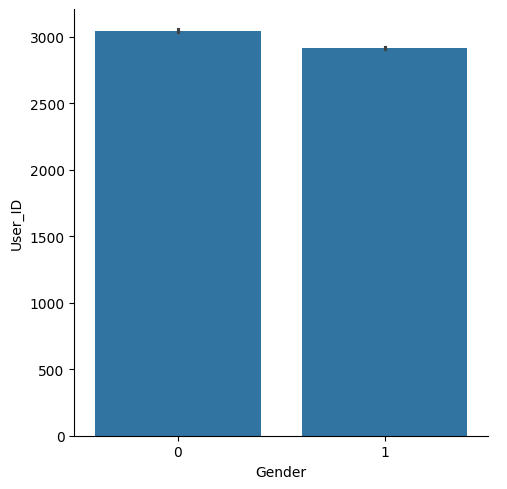

In [47]:
#visualizations to understand the distribution of the various features
sns.catplot(data=data, x='Gender', y='User_ID', kind='bar')

### Amongst all the purshases made, majority of the purchases were made by Women/Female.

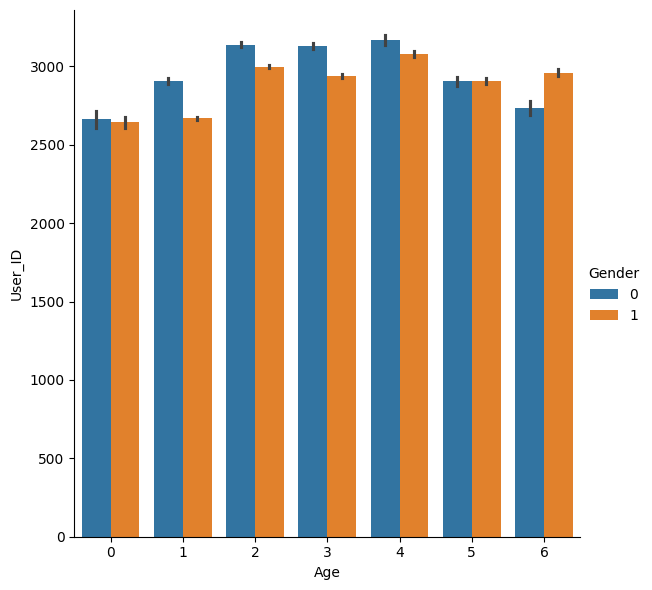

In [48]:
sns.catplot(data=data, x='Age', y='User_ID', hue='Gender', kind='bar', height=6)

###Inferences from the Plot:
1. The most frequent purchases came from the females having user ids that belong to age category 4(36-45)
2. The least frequent purchases came from the males of the age category 1(18-25), and females of age category 0(0-17).

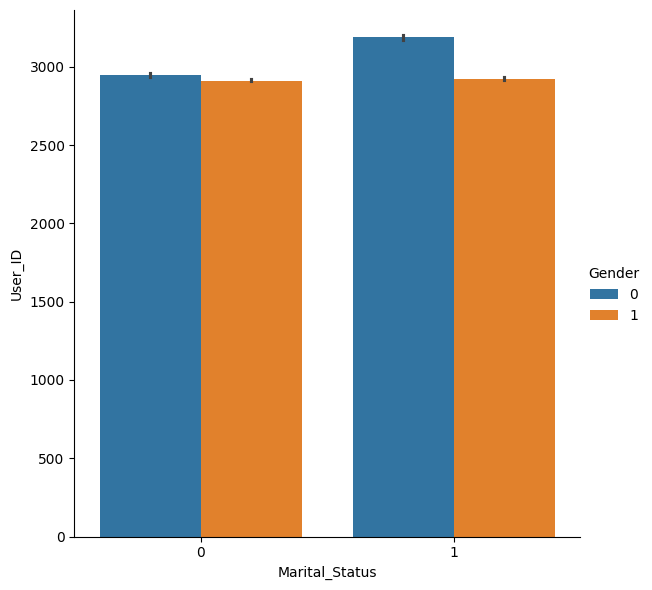

In [49]:
sns.catplot(data=data, x='Marital_Status', y='User_ID', hue='Gender', kind='bar', height=6)

### the gender ratio in unmarried customers is almost similar, whereas the married customers have a sightly higher number of females in the lot.

### Majority of the customers have stayed a year in the city.

In [53]:
#checking the correlation of the features
corr_spearman = data.corr()
corr_pearson = data.corr(method='pearson')
corr_kendall = data.corr(method='kendall')

<Axes: >

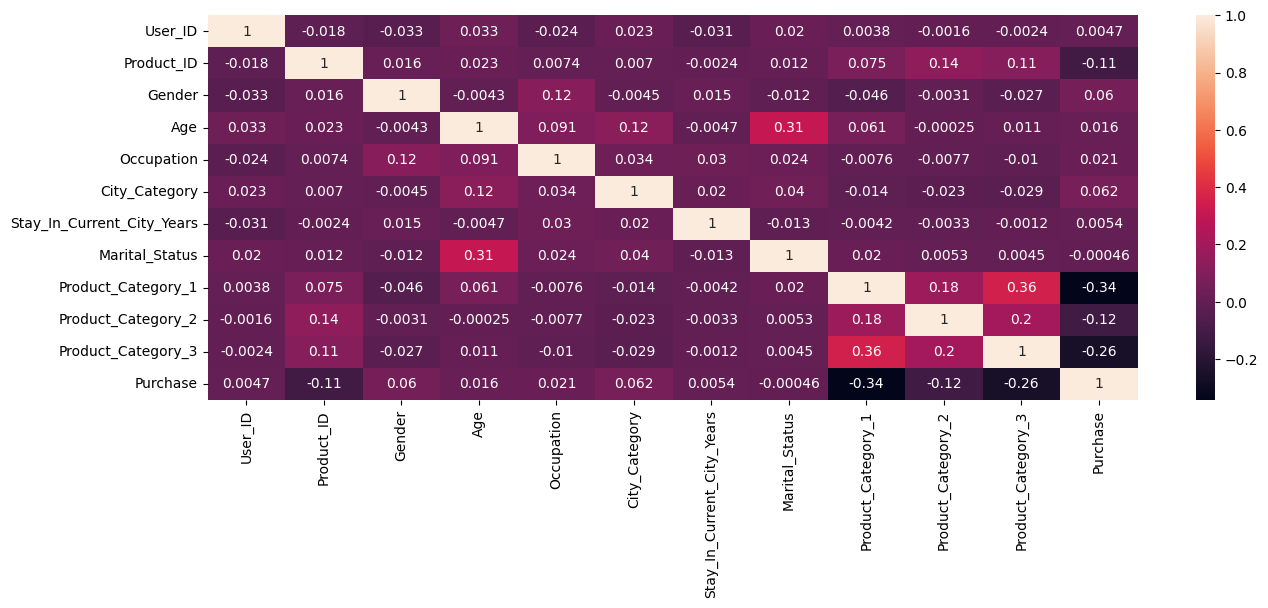

In [54]:
#spearman correlation
plt.figure(figsize=(15,5))
sns.heatmap(corr_spearman, annot=True)

<Axes: >

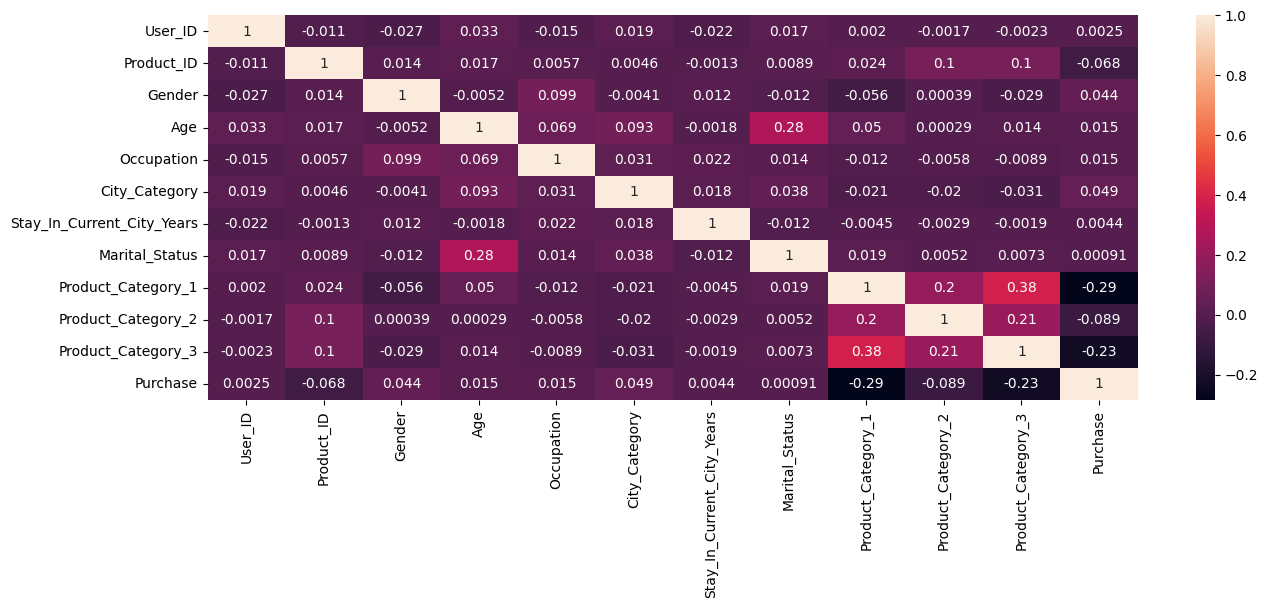

In [55]:
#kendall correlation
plt.figure(figsize=(15,5))
sns.heatmap(corr_kendall, annot=True)

<Axes: >

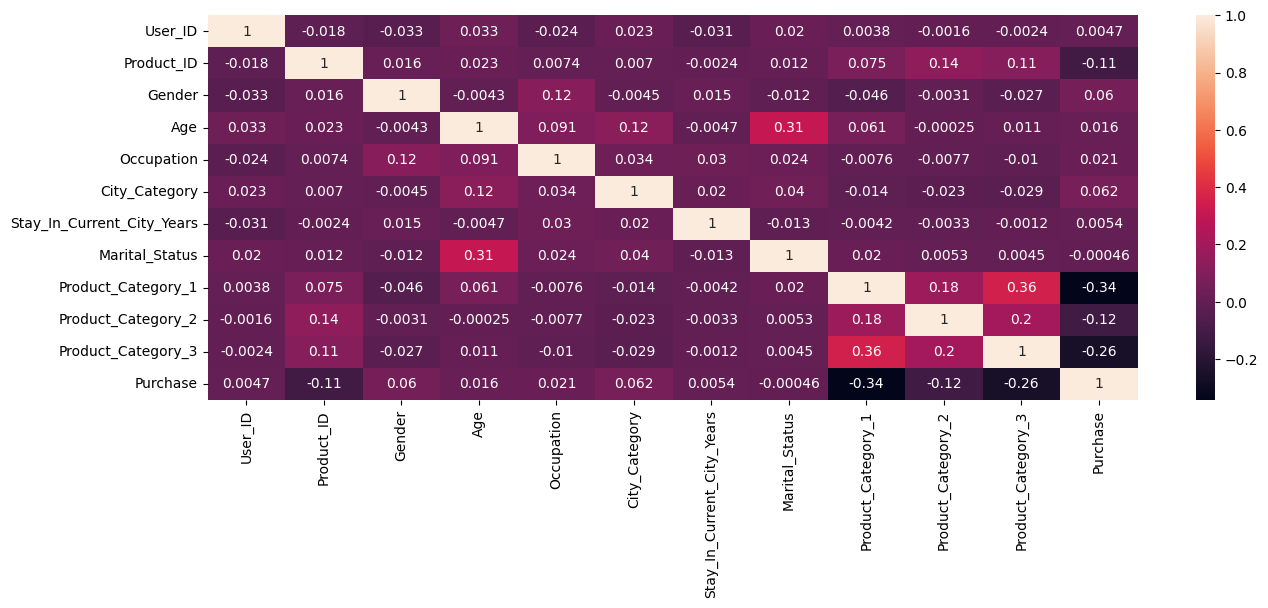

In [56]:
#pearson correlation
plt.figure(figsize=(15,5))
sns.heatmap(corr_pearson, annot=True)

## Statistical Analysis

### One Sample Test For Mean
let's Suppose, it was observed that the average purchase made by the Men of the age 18-25 was 10000. Is it still the same?

In [57]:
#null hypothesis - The mean is 10000
#alternate hypothesis - The mean is not 10000

In [105]:
new_data = data.loc[(data['Age'] == 1) & data['Gender'] == 1]

In [108]:
new_data.head()

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
97,20,2094,1,1,16,1,0,0,3,2,15,3055
98,21,3370,1,1,15,0,4+,0,1,15,7,12099
99,21,2024,1,1,15,0,4+,0,5,15,15,8797
100,21,1855,1,1,15,0,4+,0,3,11,15,10681
101,21,1065,1,1,15,0,4+,0,8,4,15,7801


In [106]:
new_data.shape

(75032, 12)

In [115]:
sample_size = 2000
sample = new_data.sample(sample_size, random_state=0)

In [116]:
pos_mean = 10000

In [117]:
sample_mean = sample['Purchase'].mean()
print(sample_mean)

9464.485


In [63]:
#one sample t-test
from scipy.stats import ttest_1samp

In [64]:
t_stat, p_value = ttest_1samp(sample['Purchase'], pos_mean)
print(t_stat, p_value)

-2.853563794298454 0.004412471104013488


In [65]:
#P-value is less than 0.05, reject the null hypothesis.
#therefore, the mean purchase for men aged 18-25 is not 10000.

### One Sample Test for Proportion
Let's Suppose, It was observed that the percentage of women of the age that spend more than 10000 was 35%. Is it still the same?

In [66]:
#null hypothesis - proportion is 35%.
#alternate hypothesis - proportion is not 35%.

data_new = data.loc[(data['Purchase'] > 10000)]

In [67]:
data_new.shape

(189450, 12)

In [119]:
data_new['Gender'].value_counts()[0]

38941

In [120]:
len(data_new['Gender'])

189450

In [69]:
#No of women in the sample
count = data_new['Gender'].value_counts()[0]

#number of observations
nobs = len(data_new['Gender'])

#hypothesised value
p0 = 0.35

In [70]:
data_new['Gender'].value_counts()/nobs

,count
Gender,
1,0.794452
0,0.205548


In [71]:
#one sample z test
from statsmodels.stats.proportion import proportions_ztest

In [72]:
z_stat, p_val = proportions_ztest(count=count,
                                  nobs=nobs,
                                  value=p0,
                                  alternative="two-sided",
                                  prop_var=False)
print(z_stat, p_val)

-155.5900345296748 0.0


In [73]:
#p-value is less than 0.05, reject the null hypothesis.
#the proportion of women spending more than 10000, is not 35%.

### Two Sample test for Means
Is the average purchase made by men and women of the age 18-25 same?

In [74]:
#null hypothesis - average spends are equal
#alternate hypothesis - average spends are not equal

data_men = data.loc[(data['Gender'] == 1)& (data['Age'] == 1)]
data_women = data.loc[(data['Gender'] == 0) & (data['Age'] == 1)]

In [75]:
#creating samples
data_men_sample = data_men.sample(500, random_state=0)
data_women_sample = data_women.sample(500, random_state=0)

In [76]:
#checking variances of the two samples
print(data_men_sample.Purchase.var())
print(data_women_sample.Purchase.var())

27975866.88793186
21722649.93944291


In [77]:
#sample means
print(data_men_sample.Purchase.mean())
print(data_women_sample.Purchase.mean())

9495.062
8410.706


In [78]:
#computing f statistic
from scipy.stats import f
F = data_men_sample.Purchase.mean()/data_women_sample.Purchase.mean()
print(F)

1.1289256811497155


In [79]:
#calculating the degrees of freedom
df1 = len(data_men_sample) - 1
df2 = len(data_women_sample) - 1

print(df1, df2)

499 499


In [80]:
#p-value
import scipy
scipy.stats.f.cdf(F, df1, df2)

0.9120282557113191

In [81]:

#the p-value is greater than 0.05, do not reject the null hypothesis.
#the alternate hypothesis is true. The average purchases are same.

In [82]:
#two sample t-test for unequal variances
from scipy.stats import ttest_ind

t_stat_2, p_val_2 = ttest_ind(data_men_sample.Purchase, data_women_sample.Purchase, equal_var=False)
print(t_stat_2, p_val_2)

3.439419704220879 0.0006074598361379589


In [83]:
#we can reject the null hypothesis using the test statistic and since p-value is less than 0.05.
#the average purchases are not the same.

### Two Sample test for Proportion
Is the percentage of men who have spend more than 10000 same for the ages 18-25 and 26-35

In [84]:
#null hypothesis - Percentage of the men in the age groups is same
#alternate hypothesis - Percentage of the men in the age groups is not same

data_age1 = data.loc[(data['Age'] == 1) & (data['Purchase'] > 10000)]
data_age2 = data.loc[(data['Age'] == 2) & (data['Purchase'] > 10000)]

In [85]:
data_age1_sample = data_age1.sample(1000, random_state=0)
data_age2_sample = data_age2.sample(1000, random_state=0)

In [86]:
count = [(data_age1_sample['Gender'] == 1).sum(), (data_age2_sample['Gender'] == 1).sum()]

nobs = [(len(data_age1_sample)), len(data_age2_sample)]

In [87]:
(data_age1_sample['Gender'] == 1).sum()

810

In [88]:
from statsmodels.stats.proportion import proportions_ztest
stat_2sample, p_value_2sample = proportions_ztest(count=count,
                                                  nobs=nobs,
                                                  value=0,
                                                  alternative='two-sided',
                                                  prop_var=False)

In [89]:
print(stat_2sample, p_value_2sample)

0.5084344113930828 0.6111487252921447


In [90]:
#p value is more than 0.05, cannot reject the null hypthesis.
#therefore, Percentage of the men in the age groups is same

In [91]:
!pip install sweetviz   #sweet visualization

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.1/15.1 MB 27.6 MB/s eta 0:00:00


In [121]:
import sweetviz as sv

In [122]:
report = sv.analyze(data)
report.show_html('harsh_report4.html')

                                             |          | [  0%]   00:00 -> (? left)

Report harsh_report4.html was generated! NOTEBOOK/COLAB USERS: the web browser MAY not pop up, regardless, the report IS saved in your notebook/colab files.


In [123]:
!pip install autoviz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.5/67.5 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 161.9/161.9 kB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 255.9/255.9 MB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 590.6/590.6 kB 47.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 84.3 MB/s eta 0:00:00
  Attempting uninstall: xgboost
    Found existing installation: xgboost 2.1.3
    Uninstalling xgboost-2.1.3:
      Successfully uninstalled xgboost-2.1.3


In [124]:
from autoviz.AutoViz_Class import AutoViz_Class

Imported v0.1.905. Please call AutoViz in this sequence:
    AV = AutoViz_Class()
    %matplotlib inline
    dfte = AV.AutoViz(filename, sep=',', depVar='', dfte=None, header=0, verbose=1, lowess=False,
               chart_format='svg',max_rows_analyzed=150000,max_cols_analyzed=30, save_plot_dir=None)


In [125]:
AV = AutoViz_Class()
report = AV.AutoViz('/content/train.csv')

    max_rows_analyzed is smaller than dataset shape 550068...
        randomly sampled 150000 rows from read CSV file
Shape of your Data Set loaded: (150000, 12)
#######################################################################################
######################## C L A S S I F Y I N G  V A R I A B L E S  ####################
#######################################################################################
Classifying variables in data set...
    Number of Numeric Columns =  2
    Number of Integer-Categorical Columns =  4
    Number of String-Categorical Columns =  3
    Number of Factor-Categorical Columns =  0
    Number of String-Boolean Columns =  1
    Number of Numeric-Boolean Columns =  1
    Number of Discrete String Columns =  0
    Number of NLP String Columns =  1
    Number of Date Time Columns =  0
    Number of ID Columns =  0
    Number of Columns to Delete =  0
    12 Predictors classified...
        No variables removed since no ID or low-information v

,Data Type,Missing Values%,Unique Values%,Minimum Value,Maximum Value,DQ Issue
User_ID,int64,0.000000,3,1000001.000000,1006040.000000,No issue
Product_ID,object,0.000000,2,,,No issue
Gender,object,0.000000,0,,,No issue
Age,object,0.000000,0,,,No issue
Occupation,int64,0.000000,0,0.000000,20.000000,No issue
City_Category,object,0.000000,0,,,No issue
Stay_In_Current_City_Years,object,0.000000,0,,,No issue
Marital_Status,int64,0.000000,0,0.000000,1.000000,No issue
Product_Category_1,int64,0.000000,0,1.000000,20.000000,Column has 1099 outliers greater than upper bound (18.50) or lower than lower bound(-9.50). Cap them or remove them.
Product_Category_2,float64,31.545333,NA,2.000000,18.000000,"47318 missing values. Impute them with mean, median, mode, or a constant value such as 123."


Number of All Scatter Plots = 3


[nltk_data] Downloading collection 'popular'
[nltk_data]    | 
[nltk_data]    | Downloading package cmudict to /root/nltk_data...
[nltk_data]    |   Unzipping corpora/cmudict.zip.
[nltk_data]    | Downloading package gazetteers to /root/nltk_data...
[nltk_data]    |   Unzipping corpora/gazetteers.zip.
[nltk_data]    | Downloading package genesis to /root/nltk_data...
[nltk_data]    |   Unzipping corpora/genesis.zip.
[nltk_data]    | Downloading package gutenberg to /root/nltk_data...
[nltk_data]    |   Unzipping corpora/gutenberg.zip.
[nltk_data]    | Downloading package inaugural to /root/nltk_data...
[nltk_data]    |   Unzipping corpora/inaugural.zip.
[nltk_data]    | Downloading package movie_reviews to
[nltk_data]    |     /root/nltk_data...
[nltk_data]    |   Unzipping corpora/movie_reviews.zip.
[nltk_data]    | Downloading package names to /root/nltk_data...
[nltk_data]    |   Unzipping corpora/names.zip.
[nltk_data]    | Downloading package shakespeare to /root/nltk_data...
[nlt

Could not draw wordcloud plot for Product_ID. 
Looks like you are missing some required data for this feature.

To download the necessary data, simply run

    python -m textblob.download_corpora

or use the NLTK downloader to download the missing data: http://nltk.org/data.html
If this doesn't fix the problem, file an issue at https://github.com/sloria/TextBlob/issues.

All Plots done
Time to run AutoViz = 34 seconds 

 ###################### AUTO VISUALIZATION Completed ########################
